# Canadian Retail Sales Forecast: 02 Forecast

**Data:** Statistics Canada, Table 20-10-0056-01, *Monthly retail trade sales by province and territory* (x 1,000 CAD).

**Your decisions (Oct 20, 2026):**
1. Seasonally adjusted data
2. Canada total + provinces + the biggest store types
3. Forecast 12 months ahead
4. Keep the COVID months (Mar 2020 – Jun 2021) but flag them for the model
5. Backtest: train on everything up to 12 months before the latest month, then forecast those 12 months and compare with what really happened
   **Added:** test two training windows (full history from 2017 vs post-COVID only from Jul 2021) and keep the more accurate one
6. Provinces → government planning; store types → retailer planning

**How to run:** click **Run → Run All Cells**, wait, then **File → Save** and **File → Download**. The first run downloads the data (about a minute).

In [1]:
# If this cell fails with "No module named statsmodels", run:  %pip install statsmodels
import io, re, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

DATA = Path("retail_data"); DATA.mkdir(exist_ok=True)
OUT = Path("retail_outputs"); OUT.mkdir(exist_ok=True)
csv_path = DATA / "20100056.csv"
if not csv_path.exists():
    r = requests.get("https://www150.statcan.gc.ca/n1/tbl/csv/20100056-eng.zip", timeout=180)
    r.raise_for_status()
    zipfile.ZipFile(io.BytesIO(r.content)).extract("20100056.csv", DATA)

raw = pd.read_csv(csv_path, low_memory=False)
print("Rows:", len(raw))
print("Columns:", raw.columns.tolist())

Rows: 80172
Columns: ['REF_DATE', 'GEO', 'DGUID', 'North American Industry Classification System (NAICS)', 'Sales', 'Adjustments', 'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID', 'VECTOR', 'COORDINATE', 'VALUE', 'STATUS', 'SYMBOL', 'TERMINATED', 'DECIMALS']


## 1. Tidy the data and see what's available

In [2]:
naics_col = next(c for c in raw.columns if "NAICS" in c or "Industry" in c)
adj_col = next(c for c in raw.columns if "Adjust" in c)
standard = {"REF_DATE", "GEO", "DGUID", "UOM", "UOM_ID", "SCALAR_FACTOR", "SCALAR_ID", "VECTOR",
            "COORDINATE", "VALUE", "STATUS", "SYMBOL", "TERMINATED", "DECIMALS", naics_col, adj_col}
extra_dims = [c for c in raw.columns if c not in standard]

d = raw.copy()
for col in extra_dims:  # e.g. a "Sales" dimension: keep the total
    vals = d[col].dropna().unique()
    keep = next((v for v in vals if "total" in str(v).lower()), d[col].value_counts().index[0])
    print(f"Extra dimension '{col}': {list(vals)[:10]} -> keeping '{keep}'")
    d = d[d[col] == keep]

d = d.rename(columns={naics_col: "store_type", adj_col: "adjustment", "VALUE": "sales_k"})
d["date"] = pd.to_datetime(d["REF_DATE"])
d = d[["date", "GEO", "store_type", "adjustment", "sales_k", "STATUS"]]
d["is_sa"] = d["adjustment"].str.lower().str.startswith("seasonally adjusted")

print("\nAdjustment values:", d["adjustment"].unique().tolist())
print("Date range:", d["date"].min().date(), "to", d["date"].max().date())
print("\nStore types in the table:")
for s in sorted(d["store_type"].unique()):
    print("  ", s)

Extra dimension 'Sales': ['Total retail sales', 'Retail e-commerce sales'] -> keeping 'Total retail sales'

Adjustment values: ['Unadjusted', 'Seasonally adjusted']
Date range: 2017-01-01 to 2026-07-01

Store types in the table:
   Automobile dealers [4411]
   Automotive parts, accessories and tire retailers [4413]
   Beer, wine and liquor retailers [4453]
   Building material and garden equipment and supplies dealers [444]
   Cannabis retailers [459993]
   Clothing and clothing accessories retailers [4581]
   Clothing, clothing accessories, shoes, jewellery, luggage and leather goods retailers [458]
   Convenience retailers and vending machine operators [44513]
   Electronics and appliances retailers [4492]
   Floor covering, window treatment and other home furnishing retailers [44912]
   Food and beverage retailers [445]
   Furniture retailers [44911]
   Furniture, floor covering, window treatment and other home furnishings retailers [4491]
   Furniture, home furnishings, electronics

## 2. Pick the series to forecast

In [3]:
PROVINCES = ["Newfoundland and Labrador", "Prince Edward Island", "Nova Scotia", "New Brunswick",
             "Quebec", "Ontario", "Manitoba", "Saskatchewan", "Alberta", "British Columbia"]
N_STORE_TYPES = 5   # change this to forecast more or fewer store types

def is_total(s):
    return "retail trade" in s.lower() and not re.search(r"\[\d{3}", s)

def subsector(s):   # 3-digit NAICS store groups like "[445]"
    return re.search(r"\[(\d{3})\]", s) is not None

total_name = next(s for s in d["store_type"].unique() if is_total(s))
latest = d["date"].max()
recent = d[(d["GEO"] == "Canada") & (d["date"] > latest - pd.DateOffset(months=12)) & d["store_type"].map(subsector)]
recent = recent[recent["is_sa"]] if recent["is_sa"].any() else recent[~recent["is_sa"]]
top_types = recent.groupby("store_type")["sales_k"].sum().nlargest(N_STORE_TYPES).index.tolist()
print("Biggest store types (last 12 months, Canada):")
for t in top_types: print("  ", t)

def get_series(geo, store_type):
    s = d[(d["GEO"] == geo) & (d["store_type"] == store_type)]
    sa = s[s["is_sa"]].set_index("date")["sales_k"].sort_index()
    if sa.notna().sum() >= 48:
        return sa.asfreq("MS"), "seasonally adjusted"
    un = s[~s["is_sa"]].set_index("date")["sales_k"].sort_index()
    return un.asfreq("MS"), "unadjusted (no SA series)"

series = {}
series[("Canada", "All retail")] = get_series("Canada", total_name)
for p in PROVINCES:
    series[(p, "All retail")] = get_series(p, total_name)
for t in top_types:
    series[("Canada", re.sub(r"\s*\[.*?\]", "", t))] = get_series("Canada", t)

summary = pd.DataFrame([{"geo": g, "store_type": t, "data_used": v, "months": s.notna().sum(),
                         "missing": s.isna().sum()} for (g, t), (s, v) in series.items()])
summary

Biggest store types (last 12 months, Canada):
   Motor vehicle and parts dealers [441]
   Food and beverage retailers [445]
   General merchandise retailers [455]
   Gasoline stations and fuel vendors [457]
   Health and personal care retailers [456]


,geo,store_type,data_used,months,missing
0,Canada,All retail,seasonally adjusted,115,0
1,Newfoundland and Labrador,All retail,seasonally adjusted,115,0
2,Prince Edward Island,All retail,seasonally adjusted,115,0
3,Nova Scotia,All retail,seasonally adjusted,115,0
4,New Brunswick,All retail,seasonally adjusted,115,0
5,Quebec,All retail,seasonally adjusted,115,0
6,Ontario,All retail,seasonally adjusted,115,0
7,Manitoba,All retail,seasonally adjusted,115,0
8,Saskatchewan,All retail,seasonally adjusted,115,0
9,Alberta,All retail,seasonally adjusted,115,0


## 3. Models

All models see the **COVID flag** (Mar 2020 – Jun 2021):
- **Naive:** next months = last known month (the simplest baseline)
- **Drift:** continue the average monthly change since July 2021 (after COVID)
- **ETS (damped trend):** exponential smoothing, trained with COVID months smoothed over so the shock doesn't distort the trend
- **ARIMA + COVID dummy:** ARIMA(1,1,1) with a 0/1 COVID flag as an extra input

In [4]:
COVID = ("2020-03-01", "2021-06-01")
H = 12

def covid_flag(idx):
    return pd.Series(((idx >= COVID[0]) & (idx <= COVID[1])).astype(float), index=idx)

def future_index(y, h=H):
    return pd.date_range(y.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")

def f_naive(y):
    return pd.Series(y.iloc[-1], index=future_index(y))

def f_drift(y):
    post = y[y.index > COVID[1]]
    step = (post.iloc[-1] - post.iloc[0]) / (len(post) - 1)
    return pd.Series(y.iloc[-1] + step * np.arange(1, H + 1), index=future_index(y))

def f_ets(y):
    y2 = y.copy()
    y2[covid_flag(y.index) == 1] = np.nan
    y2 = y2.interpolate()
    fit = ExponentialSmoothing(y2, trend="add", damped_trend=True).fit()
    return pd.Series(np.asarray(fit.forecast(H)), index=future_index(y))

def f_arima(y):
    fi = future_index(y)
    flag = covid_flag(y.index)
    if flag.sum() == 0:   # post-COVID window: nothing to flag, plain ARIMA
        fit = SARIMAX(y, order=(1, 1, 1), trend="t").fit(disp=False)
        return pd.Series(np.asarray(fit.forecast(H)), index=fi)
    fit = SARIMAX(y, exog=flag, order=(1, 1, 1), trend="t").fit(disp=False)
    return pd.Series(np.asarray(fit.forecast(H, exog=covid_flag(fi))), index=fi)

MODELS = {"Naive": f_naive, "Drift": f_drift, "ETS": f_ets, "ARIMA+COVID": f_arima}

## 4. Backtest: forecast the latest 12 months as if we didn't know them

Run twice to test whether pre-COVID data still helps:
- **Full history:** train from Jan 2017 (COVID months flagged)
- **Post-COVID only:** train from Jul 2021

Note: Drift already uses only post-COVID data, so its score is the same in both.

In [5]:
WINDOWS = {"Full history (2017+)": None, "Post-COVID only (Jul 2021+)": "2021-07-01"}

def mape(actual, pred):
    return float(np.mean(np.abs((actual - pred) / actual)) * 100)

def run_backtest(start):
    rows, preds = [], {}
    for key, (y, version) in series.items():
        y = y.dropna()
        train, test = y.iloc[:-H], y.iloc[-H:]
        if start: train = train[train.index >= start]
        for name, f in MODELS.items():
            try:
                pred = f(train); pred.index = test.index
                rows.append({"geo": key[0], "store_type": key[1], "model": name, "MAPE_%": round(mape(test, pred), 2)})
                preds[(key, name)] = pred
            except Exception as e:
                rows.append({"geo": key[0], "store_type": key[1], "model": name, "MAPE_%": np.nan})
                print("Model failed:", start, key, name, e)
    bt = pd.DataFrame(rows)
    table = bt.pivot_table(index=["geo", "store_type"], columns="model", values="MAPE_%")
    cols = [m for m in MODELS if m in table.columns]
    table["best_model"] = table[cols].idxmin(axis=1)
    table["best_MAPE_%"] = table[cols].min(axis=1)
    return bt, table, preds

results = {w: run_backtest(start) for w, start in WINDOWS.items()}
test_start, test_end = series[("Canada", "All retail")][0].dropna().index[[-H, -1]]
print(f"Backtest period: {test_start:%b %Y} to {test_end:%b %Y}  (lower MAPE = more accurate)")

Backtest period: Aug 2025 to Jul 2026  (lower MAPE = more accurate)


### Which training window is more accurate?

In [6]:
comparison = pd.DataFrame({w: r[0].groupby("model")["MAPE_%"].mean() for w, r in results.items()}).T
comparison["Best model per series"] = [r[1]["best_MAPE_%"].mean() for r in results.values()]
comparison = comparison.round(2)
comparison.to_csv(OUT / "window_comparison.csv")
print("Average error (%) by model and training window:")
display(comparison)

per_series = pd.DataFrame({w: r[1]["best_MAPE_%"] for w, r in results.items()})
per_series["better_window"] = np.where(per_series.iloc[:, 1] < per_series.iloc[:, 0], "Post-COVID", "Full history")
print("\nBest-model error (%) for each series:")
display(per_series)
print(per_series["better_window"].value_counts().to_string())

CHOSEN = comparison["Best model per series"].idxmin()
TRAIN_START = WINDOWS[CHOSEN]
bt, table, backtest_preds = results[CHOSEN]
print(f"\nChosen training window: {CHOSEN}")
for w, r in results.items():
    r[1].to_csv(OUT / f"backtest_mape_{'full' if WINDOWS[w] is None else 'postcovid'}.csv")
table

Average error (%) by model and training window:


model,ARIMA+COVID,Drift,ETS,Naive,Best model per series
Full history (2017+),2.59,2.43,2.83,3.86,2.03
Post-COVID only (Jul 2021+),2.93,2.43,3.20,3.86,2.16



Best-model error (%) for each series:


Full history (2017+)  \
geo                       store_type                                                 
Alberta                   All retail                                          2.80   
British Columbia          All retail                                          1.01   
Canada                    All retail                                          1.06   
                          Food and beverage retailers                         0.91   
                          Gasoline stations and fuel vendors                  8.64   
                          General merchandise retailers                       1.09   
                          Health and personal care retailers                  2.56   
                          Motor vehicle and parts dealers                     1.40   
Manitoba                  All retail                                          0.95   
New Brunswick             All retail                                          0.93   
Newfoundland and Labrador All retail                                          5.93   
Nova Scotia               All retail                                          0.79   
Ontario                   All retail                                          1.21   
Prince Edward Island      All retail                                          1.78   
Quebec                    All retail                                          0.52   
Saskatchewan              All retail                                          0.85   

                                                              Post-COVID only (Jul 2021+)  \
geo                       store_type                                                        
Alberta                   All retail                                                 2.91   
British Columbia          All retail                                                 1.01   
Canada                    All retail                                                 0.62   
                          Food and beverage retailers                                0.80   
                          Gasoline stations and fuel vendors                         8.64   
                          General merchandise retailers                              1.15   
                          Health and personal care retailers                         2.21   
                          Motor vehicle and parts dealers                            1.59   
Manitoba                  All retail                                                 1.44   
New Brunswick             All retail                                                 1.26   
Newfoundland and Labrador All retail                                                 7.10   
Nova Scotia               All retail                                                 1.28   
Ontario                   All retail                                                 0.98   
Prince Edward Island      All retail                                                 1.93   
Quebec                    All retail                                                 0.52   
Saskatchewan              All retail                                                 1.12   

                                                             better_window  
geo                       store_type                                        
Alberta                   All retail                          Full history  
British Columbia          All retail                          Full history  
Canada                    All retail                            Post-COVID  
                          Food and beverage retailers           Post-COVID  
                          Gasoline stations and fuel vendors  Full history  
                          General merchandise retailers       Full history  
                          Health and personal care retailers    Post-COVID  
                          Motor vehicle and parts dealers     Full history  
Manitoba                  All retail                          Full h

better_window
Full history    12
Post-COVID       4

Chosen training window: Full history (2017+)


model                                                         ARIMA+COVID  \
geo                       store_type                                        
Alberta                   All retail                                 2.80   
British Columbia          All retail                                 3.21   
Canada                    All retail                                 1.53   
                          Food and beverage retailers                1.99   
                          Gasoline stations and fuel vendors         9.27   
                          General merchandise retailers              1.09   
                          Health and personal care retailers         2.56   
                          Motor vehicle and parts dealers            1.40   
Manitoba                  All retail                                 0.95   
New Brunswick             All retail                                 0.93   
Newfoundland and Labrador All retail                                 5.93   
Nova Scotia               All retail                                 0.79   
Ontario                   All retail                                 2.79   
Prince Edward Island      All retail                                 1.78   
Quebec                    All retail                                 3.57   
Saskatchewan              All retail                                 0.85   

model                                                         Drift   ETS  \
geo                       store_type                                        
Alberta                   All retail                           2.97  3.81   
British Columbia          All retail                           1.01  1.27   
Canada                    All retail                           1.06  1.39   
                          Food and beverage retailers          1.05  0.91   
                          Gasoline stations and fuel vendors   8.64  9.04   
                          General merchandise retailers        1.29  2.35   
                          Health and personal care retailers   3.23  4.12   
                          Motor vehicle and parts dealers      1.59  1.66   
Manitoba                  All retail                           1.57  2.24   
New Brunswick             All retail                           1.49  1.80   
Newfoundland and Labrador All retail                           7.48  6.96   
Nova Scotia               All retail                           2.36  2.54   
Ontario                   All retail                           1.21  1.41   
Prince Edward Island      All retail                           2.31  3.28   
Quebec                    All retail                           0.52  1.29   
Saskatchewan              All retail                           1.12  1.28   

model                                                         Naive  \
geo                       store_type                                  
Alberta                   All retail                           4.64   
British Columbia          All retail                           1.19   
Canada                    All retail                           2.56   
                          Food and beverage retailers          1.06   
                          Gasoline stations and fuel vendors   9.04   
                          General merchandise retailers        4.62   
                          Health and personal care retailers   6.08   
                          Motor vehicle and parts dealers      1.70   
Manitoba                  All retail                           3.19   
New Brunswick             All retail                           3.85   
Newfoundland and Labrador All retail                           9.10   
Nova Scotia               All retail                           4.04   
Ontario                   All retail                           2.41   
Prince Edward Island      All retail                           4.00   
Quebec                    All retail                           2.26   
Saskatchewan       

In [7]:
print(f"Window used: {CHOSEN}")
print("Average error by model across all series (%):")
print(bt.groupby("model")["MAPE_%"].mean().round(2).sort_values().to_string())
print("\nTimes each model was best:")
print(table["best_model"].value_counts().to_string())

Window used: Full history (2017+)
Average error by model across all series (%):
model
Drift          2.43
ARIMA+COVID    2.59
ETS            2.83
Naive          3.86

Times each model was best:
best_model
ARIMA+COVID    10
Drift           5
ETS             1


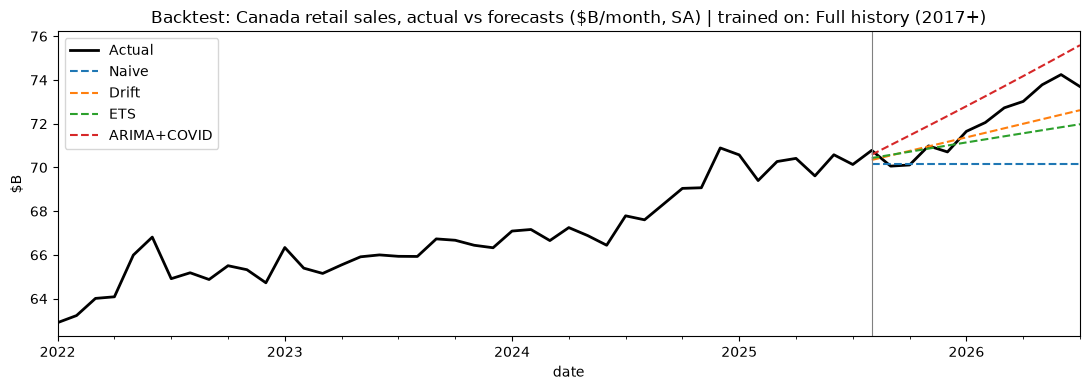

In [8]:
# Backtest picture for Canada total
y = series[("Canada", "All retail")][0].dropna()
fig, ax = plt.subplots(figsize=(11, 4))
(y[y.index >= "2022-01-01"] / 1e6).plot(ax=ax, color="black", lw=2, label="Actual")
for name in MODELS:
    p = backtest_preds.get((("Canada", "All retail"), name))
    if p is not None: (p / 1e6).plot(ax=ax, ls="--", label=name)
ax.axvline(test_start, color="grey", lw=0.8)
ax.set_title(f"Backtest: Canada retail sales, actual vs forecasts ($B/month, SA) | trained on: {CHOSEN}")
ax.set_ylabel("$B"); ax.legend(); plt.tight_layout()
plt.savefig(OUT / "backtest_canada.png", dpi=150); plt.show()

## 5. Forecast the next 12 months with each series' best model (chosen training window)

In [9]:
fc_rows = []
for key, (y, version) in series.items():
    y = y.dropna()
    if TRAIN_START: y = y[y.index >= TRAIN_START]
    best = table.loc[key, "best_model"]
    pred = MODELS[best](y)
    for dt, v in pred.items():
        fc_rows.append({"geo": key[0], "store_type": key[1], "month": dt.strftime("%Y-%m"),
                        "forecast_sales_k": round(v), "model": best, "data_used": version})
forecast = pd.DataFrame(fc_rows)
forecast.to_csv(OUT / "forecast_12m.csv", index=False)

growth = []
for key, (y, _) in series.items():
    y = y.dropna()
    f = forecast[(forecast["geo"] == key[0]) & (forecast["store_type"] == key[1])]["forecast_sales_k"]
    growth.append({"geo": key[0], "store_type": key[1],
                   "last_12m_$B": round(y.iloc[-12:].sum() / 1e6, 1),
                   "next_12m_$B": round(f.sum() / 1e6, 1),
                   "growth_%": round((f.sum() / y.iloc[-12:].sum() - 1) * 100, 1)})
growth = pd.DataFrame(growth).sort_values("growth_%", ascending=False)
growth.to_csv(OUT / "forecast_growth.csv", index=False)
growth

,geo,store_type,last_12m_$B,next_12m_$B,growth_%
14,Canada,Gasoline stations and fuel vendors,80.9,90.1,11.3
15,Canada,Health and personal care retailers,76.2,83.8,10.0
2,Prince Edward Island,All retail,3.8,4.1,9.3
1,Newfoundland and Labrador,All retail,12.8,13.9,8.4
9,Alberta,All retail,111.6,120.5,8.0
3,Nova Scotia,All retail,23.2,25.0,7.7
13,Canada,General merchandise retailers,129.2,138.2,6.9
4,New Brunswick,All retail,19.3,20.5,6.5
7,Manitoba,All retail,28.9,30.7,6.1
8,Saskatchewan,All retail,26.6,28.1,5.4


In [ ]:
keys = list(series.keys())
cols = 4; rws = int(np.ceil(len(keys) / cols))
fig, axes = plt.subplots(rws, cols, figsize=(16, 3 * rws))
for ax, key in zip(axes.flat, keys):
    y = series[key][0].dropna()
    f = forecast[(forecast["geo"] == key[0]) & (forecast["store_type"] == key[1])]
    hist = y[y.index >= "2021-01-01"]
    ax.plot(hist.index, hist.values / 1e6, color="black")
    ax.plot(pd.to_datetime(f["month"]), f["forecast_sales_k"].values / 1e6, color="tab:orange", ls="--")
    ax.set_title(f"{key[0]}: {key[1]}" if key[0] == "Canada" else key[0], fontsize=9)
    ax.set_xlabel("")
for ax in axes.flat[len(keys):]: ax.axis("off")
fig.suptitle("Monthly retail sales ($B): actual (black) and 12-month forecast (orange)", y=1.0)
plt.tight_layout(); plt.savefig(OUT / "forecasts_all.png", dpi=150); plt.show()

## 6. What you'll look at next
- Which model wins most often, and is it much better than the naive baseline?
- Which provinces are forecast to grow fastest (government planning)?
- Which store types are speeding up or slowing down (retailer planning)?

Send me the downloaded notebook (or paste the tables) and I'll write the report and the README.